In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from anndata import AnnData
import anndata as ad
import scanpy as sc
import myutils
import matplotlib.pyplot as plt
workspace,experiment=myutils.workspace()
data_dir = experiment/"scGPT/data/ms"
data_dir

PosixPath('/omics/odcf/analysis/OE0290_projects/heroes-aya_pools/AG_Thongjuea/Code/10x_multiomics/Selina/project/experiment03-scGPT/scGPT/data/ms')

In [2]:
# READ ----------------------------------------------------------------------- #
adata = sc.read(data_dir / "c_data.h5ad")
adata_test = sc.read(data_dir / "filtered_ms_adata.h5ad")

# edit categorie types and index
adata.obs["celltype"] = adata.obs["Factor Value[inferred cell type - authors labels]"].astype("category")
adata_test.obs["celltype"] = adata_test.obs["Factor Value[inferred cell type - authors labels]"].astype("category")
adata.obs["batch_id"]  = adata.obs["str_batch"] = "0"
adata_test.obs["batch_id"]  = adata_test.obs["str_batch"] = "1"          
adata.var.set_index(adata.var["gene_name"], inplace=True)
adata_test.var.set_index(adata.var["gene_name"], inplace=True)
adata_test_raw = adata_test.copy()
adata_batch0_raw = adata.copy()
adata = adata.concatenate(adata_test, batch_key="str_batch")

# batch ids to int
batch_id_labels = adata.obs["str_batch"].astype("category").cat.codes.values
adata.obs["batch_id"] = batch_id_labels
# cell types to int 
celltype_id_labels = adata.obs["celltype"].astype("category").cat.codes.values
celltypes = adata.obs["celltype"].unique()
num_types = len(np.unique(celltype_id_labels))
id2type = dict(enumerate(adata.obs["celltype"].astype("category").cat.categories))
adata.obs["celltype_id"] = celltype_id_labels
# gene names as column
adata.var["gene_name"] = adata.var.index.tolist()

In [3]:
id2type

{0: 'PVALB-expressing interneuron',
 1: 'SST-expressing interneuron',
 2: 'SV2C-expressing interneuron',
 3: 'VIP-expressing interneuron',
 4: 'astrocyte',
 5: 'cortical layer 2-3 excitatory neuron A',
 6: 'cortical layer 2-3 excitatory neuron B',
 7: 'cortical layer 4 excitatory neuron',
 8: 'cortical layer 5-6 excitatory neuron',
 9: 'endothelial cell',
 10: 'microglial cell',
 11: 'mixed excitatory neuron',
 12: 'mixed glial cell?',
 13: 'oligodendrocyte A',
 14: 'oligodendrocyte C',
 15: 'oligodendrocyte precursor cell',
 16: 'phagocyte',
 17: 'pyramidal neuron?'}

In [4]:
# COMBINED ------------------------------------------------------------------- #
print(adata)
print("\nCell index has changed:")
print("BEFORE:",adata_batch0_raw.obs.index[0])
print("AFTER:",adata.obs.index[0])
print("BEFORE:",adata_test.obs.index[0])
print("AFTER:",adata.obs.index[7844])

AnnData object with n_obs × n_vars = 21312 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 'Sample 

In [5]:
# USED FOR TRAIN / VALIDATION ------------------------------------------------ #
print(adata_batch0_raw)
adata[adata.obs["str_batch"] == "0"]

AnnData object with n_obs × n_vars = 7844 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 'Sample C

View of AnnData object with n_obs × n_vars = 7844 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', '

In [6]:
# USED FOR FINAL TEST -------------------------------------------------------- #
print(adata_test_raw)
adata[adata.obs["str_batch"] == "1"]

AnnData object with n_obs × n_vars = 13468 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 'Sample 

View of AnnData object with n_obs × n_vars = 13468 × 3000
    obs: 'Sample Characteristic[organism]', 'Sample Characteristic Ontology Term[organism]', 'Sample Characteristic[individual]', 'Sample Characteristic Ontology Term[individual]', 'Sample Characteristic[sex]', 'Sample Characteristic Ontology Term[sex]', 'Sample Characteristic[age]', 'Sample Characteristic Ontology Term[age]', 'Sample Characteristic[developmental stage]', 'Sample Characteristic Ontology Term[developmental stage]', 'Sample Characteristic[organism part]', 'Sample Characteristic Ontology Term[organism part]', 'Sample Characteristic[sampling site]', 'Sample Characteristic Ontology Term[sampling site]', 'Sample Characteristic[disease]', 'Sample Characteristic Ontology Term[disease]', 'Sample Characteristic[organism status]', 'Sample Characteristic Ontology Term[organism status]', 'Sample Characteristic[cause of death]', 'Sample Characteristic Ontology Term[cause of death]', 'Sample Characteristic[clinical history]', 

# UMPAS

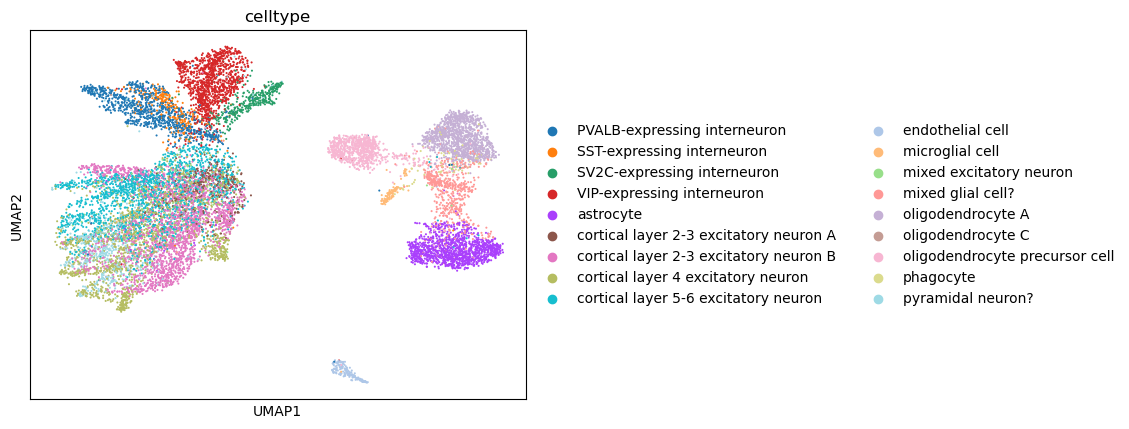

In [7]:
sc.pl.umap(adata_test, color='celltype')

In [8]:
print('adata combined')
print(f"str_batch: {', '.join(adata.obs.str_batch.unique())}")
print(f"celltype: {', '.join(adata.obs.celltype.cat.categories.to_list())}")
print('')
print('adata_test')
print(f"str_batch: {''.join(adata_test.obs.str_batch.unique())}")
print(f"celltype: {', '.join(adata_test.obs.celltype.cat.categories.to_list())}")

adata combined
str_batch: 0, 1
celltype: PVALB-expressing interneuron, SST-expressing interneuron, SV2C-expressing interneuron, VIP-expressing interneuron, astrocyte, cortical layer 2-3 excitatory neuron A, cortical layer 2-3 excitatory neuron B, cortical layer 4 excitatory neuron, cortical layer 5-6 excitatory neuron, endothelial cell, microglial cell, mixed excitatory neuron, mixed glial cell?, oligodendrocyte A, oligodendrocyte C, oligodendrocyte precursor cell, phagocyte, pyramidal neuron?

adata_test
str_batch: 1
celltype: PVALB-expressing interneuron, SST-expressing interneuron, SV2C-expressing interneuron, VIP-expressing interneuron, astrocyte, cortical layer 2-3 excitatory neuron A, cortical layer 2-3 excitatory neuron B, cortical layer 4 excitatory neuron, cortical layer 5-6 excitatory neuron, endothelial cell, microglial cell, mixed excitatory neuron, mixed glial cell?, oligodendrocyte A, oligodendrocyte C, oligodendrocyte precursor cell, phagocyte, pyramidal neuron?


In [ ]:
adata_test = adata[adata.obs["str_batch"] == "1"]
adata = adata[adata.obs["str_batch"] == "0"]
adata_test.shape, adata.shape

((13468, 3000), (7844, 3000))

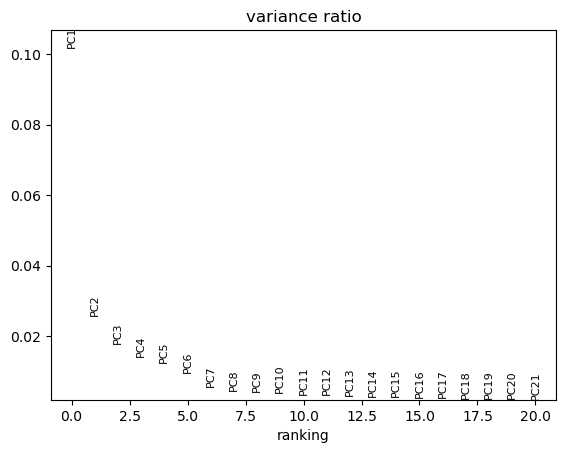

In [ ]:
adata_combined = adata.copy()
sc.tl.pca(adata_combined, n_comps=50, zero_center=True, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata_combined, n_pcs=20)

In [12]:
sc.pp.neighbors(adata_combined, n_neighbors=10, n_pcs=20, use_rep='X_pca')
sc.tl.leiden(adata_combined, flavor='igraph',resolution=0.85,random_state=0,n_iterations=2,directed=False)
print(len(adata_combined.obs.leiden.cat.categories))

19


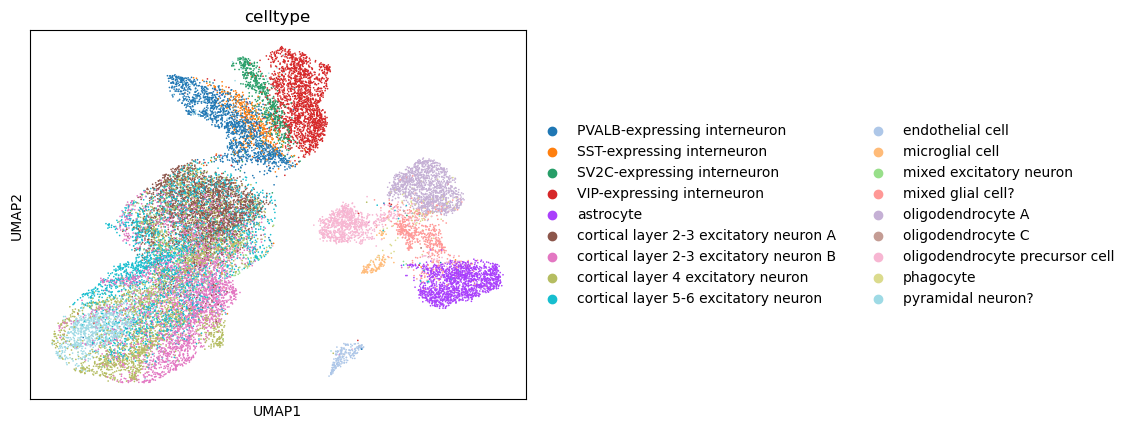

In [13]:
sc.tl.umap(adata_combined)
sc.pl.umap(adata_combined, color=["celltype"])


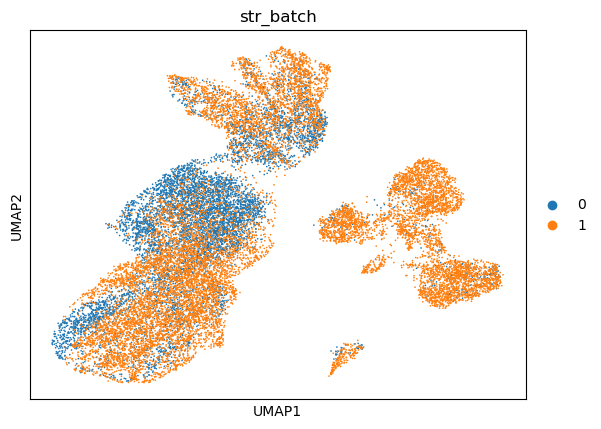

In [14]:
sc.pl.umap(adata_combined, color=["str_batch"])

In [15]:
sum(adata_combined.obs.str_batch == '0') / adata_combined.n_obs, sum(adata_combined.obs.str_batch == '1') / adata_combined.n_obs

(0.3680555555555556, 0.6319444444444444)

In [16]:
adata_test.obs["str_batch"].astype("category").cat.codes.values

array([0, 0, 0, ..., 0, 0, 0], dtype=int8)

In [42]:
adata_combined.obs["batch_id"].iloc[12100],adata_combined.obs["str_batch"].iloc[12100]

(1, '1')

In [43]:
adata_test.obs["batch_id"].iloc[1],adata_test.obs["str_batch"].iloc[1]

(1, '1')

In [30]:
cell_counts = pd.crosstab(adata_combined.obs['celltype'], adata_combined.obs['batch_id'])
cell_counts

batch_id,0,1
celltype,,
PVALB-expressing interneuron,569,878
SST-expressing interneuron,172,258
SV2C-expressing interneuron,234,344
VIP-expressing interneuron,662,1158
astrocyte,154,1330
cortical layer 2-3 excitatory neuron A,2010,314
cortical layer 2-3 excitatory neuron B,1019,2178
cortical layer 4 excitatory neuron,1284,1504
cortical layer 5-6 excitatory neuron,997,1732


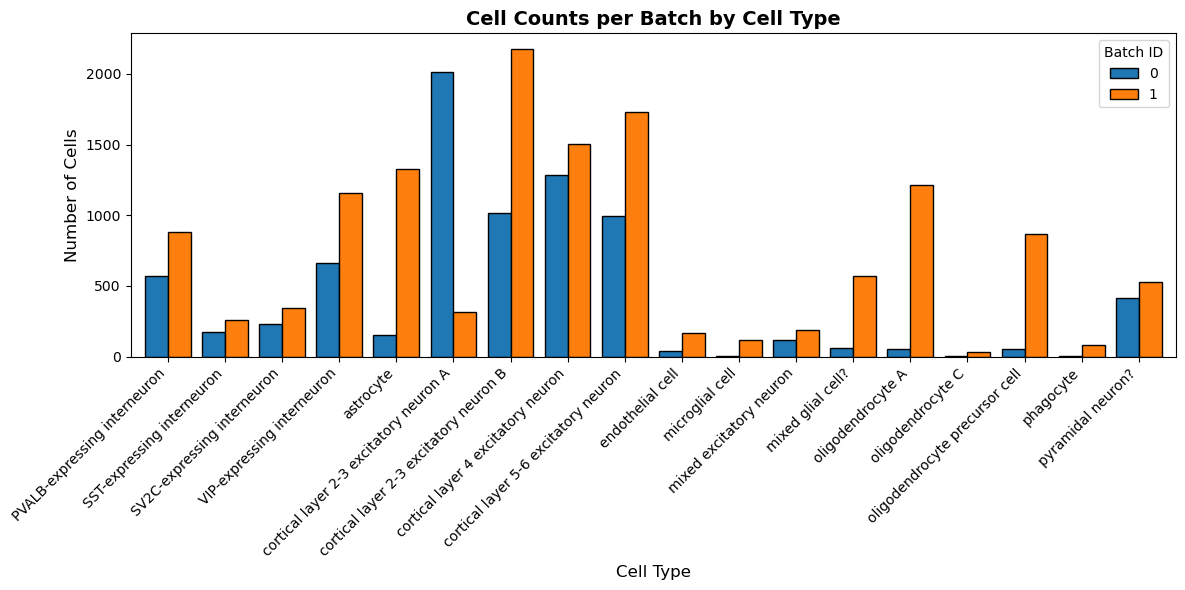

In [35]:
cell_counts.plot(kind='bar', stacked=False, figsize=(12, 6), edgecolor='black', width=0.8)

# 3. Add layout styling
plt.title("Cell Counts per Batch by Cell Type", fontsize=14, fontweight='bold')
plt.xlabel("Cell Type", fontsize=12)
plt.ylabel("Number of Cells", fontsize=12)
plt.xticks(rotation=45, ha='right')  # Tilts the labels so they don't overlap
plt.legend(title="Batch ID")
plt.tight_layout()

plt.show()